# Customer Segmentation Using K-Means Clustering

## Project Overview

This notebook applies K-Means clustering to segment customers using **Annual Income (k$)** and **Spending Score (1-100)**. It covers data inspection, feature scaling, selecting a candidate number of clusters, model evaluation, visualization, cluster profiling, and business interpretation.

# Business Problem

A company wants to understand customer income and spending patterns so it can develop more relevant marketing strategies. K-Means clustering can group customers with similar values for Annual Income and Spending Score. These groups can then be explored to understand differences in customer behavior.

The current model uses **Annual Income (k$)** and **Spending Score (1-100)**. Gender and Age are not used as clustering features in this version.

## Objective

Develop a K-Means clustering model that groups customers using:
- Annual Income (k$)
- Spending Score (1-100)

The goal is to discover customer segments and describe their characteristics. The model does not predict whether a customer will purchase a product.

## Workflow

1. Import the required libraries.
2. Load and inspect the dataset.
3. Validate the data.
4. Select the features used for clustering.
5. Scale the features.
6. Use the Elbow Method to inspect candidate values of K.
7. Compare candidate cluster counts using the silhouette score.
8. Fit the final K-Means model and assign cluster labels.
9. Visualize the clusters.
10. Profile and interpret the clusters.
11. Export the clustered dataset.

### Import the required libraries.

In [1]:
# Import the required libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

### Load and inspect the dataset.

In [2]:
# Read the input data
dataset = pd.read_csv("../data/Mall_Customers.csv")

In [3]:
# Print the first five rows of the dataset
dataset.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Data validation

In [4]:
# Validate the dataset before preprocessing
print("Dataset shape:", dataset.shape)

print("\nMissing values:")
print(dataset.isnull().sum())

print("\nDuplicate rows:", dataset.duplicated().sum())

print("\nData types:")
print(dataset.dtypes)

Dataset shape: (200, 5)

Missing values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0

Data types:
CustomerID                 int64
Genre                     object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


In [5]:
# Print the first five rows of the dataset
dataset.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [6]:
# CustomerID is an identifier, not a useful clustering feature.
# Keep the original customer attributes available for later profiling.
dataset = dataset.drop(columns=["CustomerID"])

In [7]:
# Print the first five rows of the dataset
dataset.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


### Feature selection

In [8]:
# Select the features used to create the clusters
features = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = dataset[features].copy()

In [9]:
# Preview the selected features
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


## Feature scaling

In [10]:
# Standardize the features so their scales are comparable
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Select the Number of Clusters

The Elbow Method examines how the within-cluster sum of squares (WCSS) changes as K increases. Use it to identify a reasonable range of candidate values, then compare those candidates with the silhouette score.

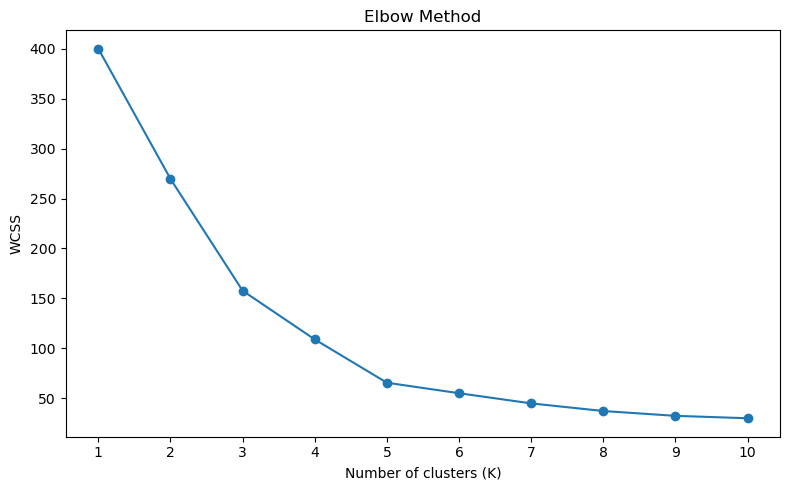

In [11]:
# Calculate WCSS for K values from 1 to 10
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.tight_layout()
plt.show()

In [12]:
# Display WCSS values for reference
pd.DataFrame({
    "K": range(1, 11),
    "WCSS": wcss
})

,K,WCSS
0,1,400.000000
1,2,269.691012
2,3,157.704008
3,4,108.921317
4,5,65.568408
5,6,55.057348
6,7,44.864756
7,8,37.228188
8,9,32.392268
9,10,29.981898


In [13]:
# Compare candidate values of K using the silhouette score
silhouette_results = []

for k in range(2, 11):
    candidate_model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    candidate_labels = candidate_model.fit_predict(X_scaled)

    silhouette_results.append({
        "K": k,
        "WCSS": candidate_model.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, candidate_labels)
    })

silhouette_df = pd.DataFrame(silhouette_results)
silhouette_df.round(3)

,K,WCSS,Silhouette Score
0,2,269.691,0.321
1,3,157.704,0.467
2,4,108.921,0.494
3,5,65.568,0.555
4,6,55.057,0.540
5,7,44.865,0.528
6,8,37.228,0.455
7,9,32.392,0.457
8,10,29.982,0.443


## Fit the Final K-Means Model

The Elbow Method and silhouette scores should be considered together. In this project, K = 5 is used as the selected candidate.

In [14]:
# Fit K-Means with the selected number of clusters
kmeans = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=10,
    random_state=42
)
cluster_labels = kmeans.fit_predict(X_scaled)

In [15]:
# Inspect the cluster label assigned to each customer
cluster_labels

array([4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 0,
       4, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 3, 1, 0, 1, 3, 1, 3, 1,
       0, 1, 3, 1, 3, 1, 3, 1, 3, 1, 0, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1], dtype=int32)

In [16]:
# Create a separate copy of the customer data
clustered_customers = dataset.copy()

In [17]:
# Preview the customer data before adding cluster labels
clustered_customers.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


## Cluster Assignment

In [18]:
# Add a cluster label to each customer
clustered_customers["Cluster_group"] = cluster_labels

clustered_customers.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster_group
0,Male,19,15,39,4
1,Male,21,15,81,2
2,Female,20,16,6,4
3,Female,23,16,77,2
4,Female,31,17,40,4


In [19]:
# Export the clustered customer data; create the output folder if needed
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "k-means_cluster.csv"
clustered_customers.to_csv(output_file, index=False)

print(f"Clustered data saved to: {output_file.resolve()}")

Clustered data saved to: D:\Hope\AI Course Tamil\ML\Clustering\outputs\k-means_cluster.csv


## Cluster Centroids

K-Means was fitted using scaled features, so its stored centroids are in standardized units. Convert them back to the original units to make them easier to interpret.

In [20]:
# Convert centroids back to the original feature scale
cluster_centers_original = scaler.inverse_transform(kmeans.cluster_centers_)

cluster_centers_df = pd.DataFrame(
    cluster_centers_original,
    columns=features
)
cluster_centers_df.index.name = "Cluster_group"

cluster_centers_df.round(2)

,Annual Income (k$),Spending Score (1-100)
Cluster_group,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


In [21]:
# Inspect the labels assigned to the customers
clustered_customers["Cluster_group"].value_counts().sort_index()

Cluster_group
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

## Cluster Visualization

Plot Annual Income against Spending Score, with color indicating the assigned cluster.

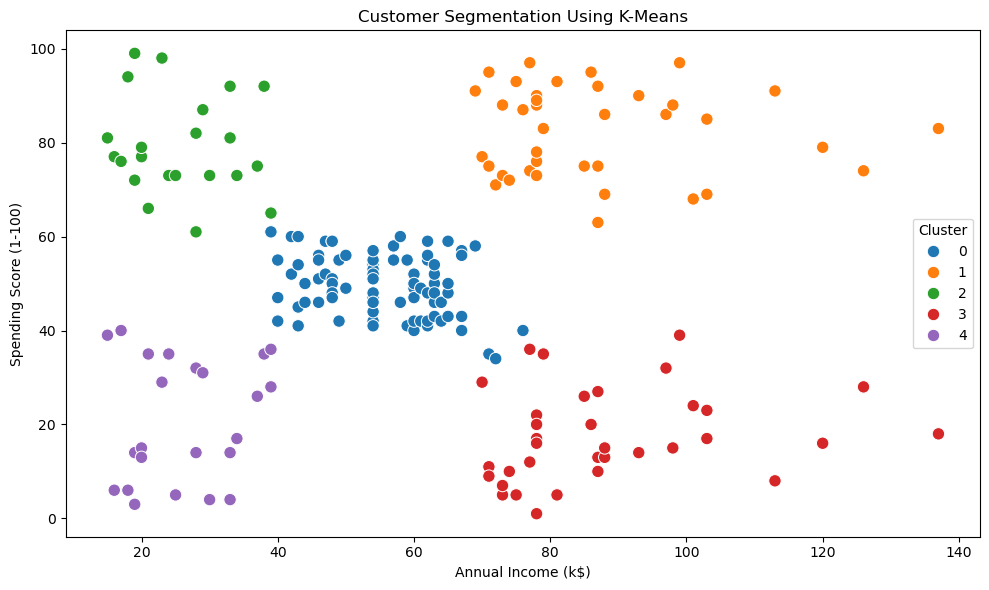

In [22]:
# Visualize the clusters using explicit feature names
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clustered_customers,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster_group",
    palette="tab10",
    s=80
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

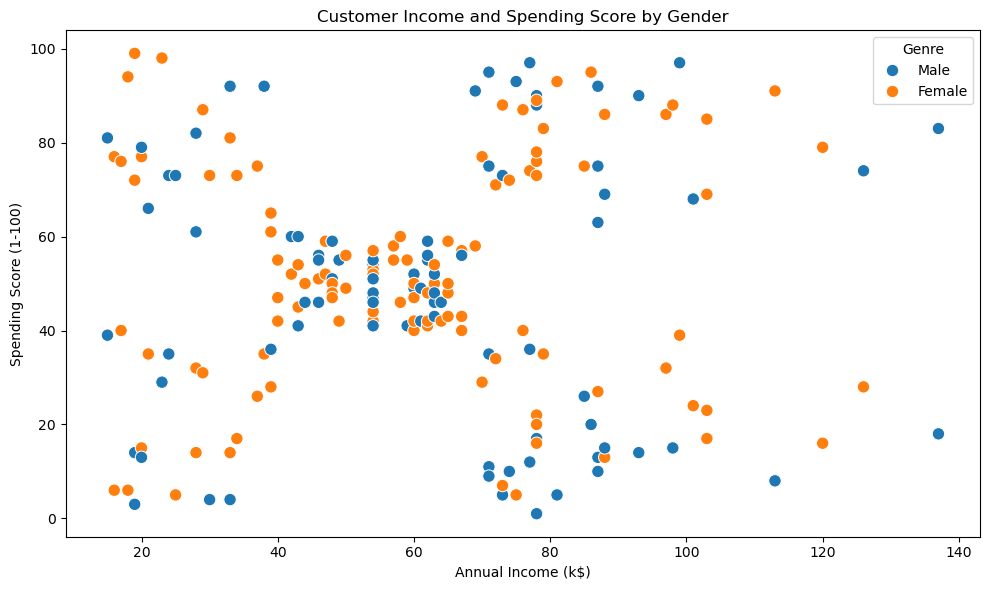

In [23]:
# Optional exploratory view: compare Gender across the income-spending space.
# Gender is not used by the current K-Means model.
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clustered_customers,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Genre",
    s=80
)

plt.title("Customer Income and Spending Score by Gender")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

## Cluster profiling

The table below reports the number and percentage of customers in each cluster, along with the average income and spending score. Use these values to describe the segments; cluster numbers are arbitrary labels.

In [24]:
# Calculate descriptive statistics for each cluster
cluster_profile = clustered_customers.groupby("Cluster_group").agg(
    Customer_Count=("Cluster_group", "size"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"] / len(clustered_customers) * 100
).round(2)

cluster_profile

,Customer_Count,Average_Income,Average_Spending_Score,Customer_Percentage
Cluster_group,,,,
0,81,55.30,49.52,40.5
1,39,86.54,82.13,19.5
2,22,25.73,79.36,11.0
3,35,88.20,17.11,17.5
4,23,26.30,20.91,11.5


## Interpreting the Cluster Profiles

- **Cluster 0 — Medium income, medium spending:** 81 customers (40.5%); average income **$55.30k**, spending score **49.52**.
- **Cluster 1 — High income, high spending:** 39 customers (19.5%); average income **$86.54k**, spending score **82.13**.
- **Cluster 2 — Low income, high spending:** 22 customers (11.0%); average income **$25.73k**, spending score **79.36**.
- **Cluster 3 — High income, low spending:** 35 customers (17.5%); average income **$88.20k**, spending score **17.11**.
- **Cluster 4 — Low income, low spending:** 23 customers (11.5%); average income **$26.30k**, spending score **20.91**.

**Key insight:** Customers with similar incomes can have very different spending scores. Cluster numbers are arbitrary labels, not rankings. These profiles describe this dataset; validate marketing decisions with transaction or campaign data.
